# Fleet Force | Sprint 2 | Machine Learning & Modelling
## EDA, pré-processamento e insights sobre a frota real da UFMG (2025)

**Challenge Sem Parar, FIAP 1TIAPR 2026. Equipe Fleet Force.** Professor: Mario Andre de Deus.

**Objetivo da entrega:** escolher uma base pública ligada à gestão de frotas, fazer a análise exploratória (estatísticas descritivas, gráficos, inconsistências), limpar e preparar os dados e tirar padrões que conversem com o problema de negócio da Sem Parar.

**Ligação com a Sprint 1.** Na Sprint 1 propusemos uma regressão do custo de combustível por veículo, com baseline histórico, preços da ANP como variável externa e validação temporal. O feedback pediu três coisas para as próximas entregas: mostrar ganho sobre o baseline com MAE, RMSE e MAPE; avaliar a representatividade dos dados (a Sprint 1 usava dados sintéticos); aprofundar tipo de veículo, região e padrão de uso. Esta Sprint responde à segunda e à terceira: trocamos os dados sintéticos por uma **frota pública real** e olhamos custo por tipo de veículo e por padrão de uso. A primeira (métricas contra o baseline) fica para a Sprint 3, quando houver modelo treinado; a seção 9 explica o porquê e deixa a base pronta.

**Fontes**
| Base | O que é | Origem |
|---|---|---|
| `despesa-veiculos-ufmg-2025.pdf` | Relatório de Despesas por Veículo do sistema SISFROTA da UFMG, de 01/01 a 31/12/2025: uma linha por veículo com ordens de serviço, mão de obra, peças, pneus, abastecimento, lavagem, km rodado, km/L e custo por km | Relatório público de despesas da frota da UFMG, guardado no repositório do grupo `Joaopdiasventura/fleet-force-calculation-engine` |
| `anp_mg_2026s1.csv` | Preços de venda de combustíveis coletados pela ANP em postos de Minas Gerais, 1º semestre de 2026 | Recorte de MG do arquivo `Preços semestrais - AUTOMOTIVOS_2026.01.csv` da ANP (mesmo repositório); o arquivo nacional tem 72 MB |

Os CSVs de entrada são gerados por `extrair_dados.py`, que lê a tabela do PDF pela posição das colunas e filtra a ANP para MG. O notebook parte desses CSVs.

In [1]:
from pathlib import Path
import re
import unicodedata

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 200)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 100

DADOS = Path("dados")
SEMENTE = 42  # usada na divisão treino/teste preparada na seção 9

## 1. Problema de negócio

A Sem Parar quer que o gestor de frota entenda **para onde vai o dinheiro de cada veículo** e consiga **antecipar o custo** e agir sobre os veículos fora do padrão. Para a Fleet Force isso vira duas perguntas que um modelo pode responder:

1. **Quanto um veículo vai custar** (combustível e manutenção) dado o tipo e o quanto roda? Alvo candidato: despesa total ou custo por km.
2. **Quais veículos estão fora do padrão** do próprio grupo (consumo ou custo por km muito acima dos pares)?

Antes de modelar, a EDA precisa responder: os dados são confiáveis? Quais variáveis explicam o custo? Que limpeza é obrigatória?

## 2. Carga dos dados e conferência com o relatório original

In [2]:
bruto = pd.read_csv(DADOS / "frota_ufmg_2025_bruto.csv")
anp = pd.read_csv(DADOS / "anp_mg_2026s1.csv", parse_dates=["data_coleta"])
print(f"Frota: {bruto.shape[0]} linhas x {bruto.shape[1]} colunas | {bruto['placa'].nunique()} placas distintas")
print(f"ANP MG: {anp.shape[0]:,} coletas de preço x {anp.shape[1]} colunas")
bruto.head()

Frota: 232 linhas x 15 colunas | 217 placas distintas
ANP MG: 45,356 coletas de preço x 5 colunas


,placa,modelo,qtd_os,mao_obra_interna,mao_obra_externa,pecas,pneus,abastecimento,lubrificante,lavagem,km,km_l_relatorio,despesa_total,custo_km_relatorio,pagina_pdf
0,EXY2I64,MASTER,1.00,19.57,0.00,401.48,0.00,"3,650.38",0.00,97.90,"4,431.00",8.77,"4,169.33",0.94,1
1,GMF1396,CAMINHAO,6.00,123.45,"3,454.33","15,579.99",0.00,"2,785.84",0.00,63.63,698.00,1.98,"22,007.24",31.53,1
2,GMF1756,VAN SPRINTER,0.00,0.00,0.00,0.00,0.00,"1,312.78",0.00,0.00,"1,165.00",5.64,"1,312.78",1.13,1
3,GMF2414,CAMINHAO,3.00,0.00,294.70,503.89,0.00,"7,789.40",0.00,127.27,"2,807.00",2.43,"8,715.26",3.10,1
4,GMF2794,CAMINHAO 608,0.00,0.00,0.00,0.00,0.00,"3,464.63",0.00,0.00,"4,235.00",7.93,"3,464.63",0.82,1


O PDF termina com uma linha de total. Se a extração estiver certa, a soma de cada coluna tem que bater com ela. Valores impressos no relatório: 571 ordens de serviço, 1.964.906 km, R$ 1.315.462,14 de abastecimento e R$ 2.383.556,97 de despesa total (lidos da última página do PDF).

In [3]:
total_impresso = {"qtd_os": 571, "km": 1_964_906, "abastecimento": 1_315_462.14, "despesa_total": 2_383_556.97}
conferencia = pd.DataFrame({
    "soma_extraida": {c: bruto[c].sum() for c in total_impresso},
    "total_impresso_no_pdf": total_impresso,
})
conferencia["diferenca"] = conferencia["soma_extraida"] - conferencia["total_impresso_no_pdf"]
display(conferencia)

custos = ["mao_obra_interna", "mao_obra_externa", "pecas", "pneus", "abastecimento", "lubrificante", "lavagem"]
fecha = (bruto[custos].sum(axis=1) - bruto["despesa_total"]).abs() <= 0.02
print(f"Linhas em que a soma das colunas de custo fecha com a despesa total: {fecha.sum()} de {len(bruto)}")

,soma_extraida,total_impresso_no_pdf,diferenca
qtd_os,571.00,571.00,0.00
km,"1,964,906.00","1,964,906.00",0.00
abastecimento,"1,315,462.15","1,315,462.14",0.01
despesa_total,"2,383,556.98","2,383,556.97",0.01


Linhas em que a soma das colunas de custo fecha com a despesa total: 232 de 232


As somas batem com o total impresso (diferença de centavos, arredondamento) e as colunas de custo fecham com a despesa total em todas as linhas. A extração do PDF é confiável; os problemas que aparecerem daqui em diante são do próprio relatório.

## 3. Visão geral

In [4]:
bruto.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 232 entries, 0 to 231
Data columns (total 15 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   placa               232 non-null    object 
 1   modelo              232 non-null    object 
 2   qtd_os              232 non-null    float64
 3   mao_obra_interna    232 non-null    float64
 4   mao_obra_externa    232 non-null    float64
 5   pecas               232 non-null    float64
 6   pneus               232 non-null    float64
 7   abastecimento       232 non-null    float64
 8   lubrificante        232 non-null    float64
 9   lavagem             232 non-null    float64
 10  km                  232 non-null    float64
 11  km_l_relatorio      232 non-null    float64
 12  despesa_total       232 non-null    float64
 13  custo_km_relatorio  232 non-null    float64
 14  pagina_pdf          232 non-null    int64  
dtypes: float64(12), int64(1), object(2)
memory usage: 27.3+ K

In [5]:
bruto.describe().T

,count,mean,std,min,25%,50%,75%,max
qtd_os,232.00,2.46,2.27,0.00,1.00,2.00,4.00,12.00
mao_obra_interna,232.00,137.14,189.47,0.00,0.00,61.73,241.67,982.11
mao_obra_externa,232.00,408.07,"1,842.65",0.00,0.00,0.00,281.83,"25,552.09"
pecas,232.00,"2,838.68","5,506.50",0.00,0.00,724.97,"3,549.77","48,662.09"
pneus,232.00,"1,052.61","6,232.43",0.00,0.00,0.00,0.00,"89,621.34"
abastecimento,232.00,"5,670.10","6,515.91",0.00,"1,542.59","3,499.39","8,146.10","61,048.40"
lubrificante,232.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
lavagem,232.00,167.37,156.72,0.00,39.16,117.96,260.65,916.99
km,232.00,"8,469.42","25,732.86",0.00,"1,709.00","4,232.50","9,529.75","378,514.00"
km_l_relatorio,232.00,12.31,63.83,0.00,5.34,7.97,9.90,972.09


In [6]:
print("Valores ausentes (NaN) por coluna:", int(bruto.isna().sum().sum()))
print()
print("Mas zero também pode ser ausência de registro:")
print(f"  km = 0 ............................ {(bruto['km'] == 0).sum()} linhas")
print(f"  km/L = 0 .......................... {(bruto['km_l_relatorio'] == 0).sum()} linhas")
print(f"  abastecimento = 0 ................. {(bruto['abastecimento'] == 0).sum()} linhas")
print(f"  km = 0 com abastecimento > 0 ...... {((bruto['km'] == 0) & (bruto['abastecimento'] > 0)).sum()} linhas")
print(f"  lubrificante = 0 .................. {(bruto['lubrificante'] == 0).sum()} linhas (coluna inteira zerada)")

Valores ausentes (NaN) por coluna: 0

Mas zero também pode ser ausência de registro:
  km = 0 ............................ 19 linhas
  km/L = 0 .......................... 19 linhas
  abastecimento = 0 ................. 18 linhas
  km = 0 com abastecimento > 0 ...... 1 linhas
  lubrificante = 0 .................. 232 linhas (coluna inteira zerada)


Não há `NaN`, mas o zero esconde falta de registro: veículo que abasteceu e aparece com 0 km não ficou parado, só não teve o hodômetro lançado. A coluna de lubrificante está zerada em todas as linhas (o gasto com lubrificante, se existe, deve estar dentro de peças ou mão de obra) e não traz informação.

## 4. Inconsistências encontradas

### 4.1 Placas que aparecem em mais de uma linha

In [7]:
repetidas = bruto[bruto["placa"].duplicated(keep=False)].sort_values(["placa", "pagina_pdf"])
print(f"{repetidas['placa'].nunique()} placas aparecem em {len(repetidas)} linhas")
colunas_exatas = [c for c in bruto.columns if c != "pagina_pdf"]
exatas = bruto[bruto.duplicated(subset=colunas_exatas, keep=False)]
print(f"Duplicatas exatas (todas as colunas iguais): {len(exatas)} linhas -> placa {exatas['placa'].unique().tolist()}")
repetidas[["placa", "modelo", "qtd_os", "pecas", "abastecimento", "km", "km_l_relatorio", "despesa_total"]]

13 placas aparecem em 28 linhas


Duplicatas exatas (todas as colunas iguais): 2 linhas -> placa ['GMF7102']


,placa,modelo,qtd_os,pecas,abastecimento,km,km_l_relatorio,despesa_total
7,GMF3245,PICK-UP S10 2.2,3.00,100.97,0.00,0.00,0.00,457.08
8,GMF3245,PICK-UP S10 2.2,0.00,0.00,"4,096.46",0.00,0.00,"4,096.46"
22,GMF5090,KOMBI -,2.00,208.12,0.00,0.00,0.00,495.09
23,GMF5090,KOMBI -,0.00,0.00,"2,957.78","3,518.00",7.99,"2,987.15"
30,GMF5165,UNO MILLE FIRE,1.00,90.75,0.00,0.00,0.00,110.33
31,GMF5165,UNO MILLE FIRE,0.00,0.00,"2,560.96","3,984.00",10.04,"2,590.33"
43,GMF5418,KOMBI -,0.00,0.00,275.88,200.00,4.92,275.88
44,GMF5418,KOMBI -,0.00,0.00,0.00,0.00,0.00,19.58
69,GMF6458,SENTRA 2.0,0.00,0.00,"2,118.49","2,604.00",8.02,"2,147.86"
70,GMF6458,SENTRA 2.0,0.00,0.00,0.00,0.00,0.00,444.62


São dois problemas diferentes, com tratamentos diferentes:

* **GMF7102 é duplicata exata**: a mesma linha impressa duas vezes. O total do relatório soma as duas, ou seja, o próprio relatório superestima a despesa da frota em R$ 16.040,24. Removemos uma das cópias.
* **As outras placas são linhas fracionadas**: o sistema separou o mesmo veículo em uma linha de manutenção (peças, OS, km zero) e outra de abastecimento (km e km/L). Não são duplicatas; apagar uma delas perderia custo. O certo é **somar por placa**.

### 4.2 Rótulos de modelo

In [8]:
print(f"{bruto['modelo'].nunique()} rótulos distintos de modelo")
print(sorted(bruto["modelo"].unique()))

79 rótulos distintos de modelo
['ALLEGRO R', 'AMAROK CD', 'AMBULANCIA', 'ATHENAS', 'CAMINHAO', 'CAMINHAO 608', 'CAMINHAO 710', 'CAMINHAO 8500', 'CAMINHAO BAU', 'CAMINHAO HR', 'CAVALO MEC.', 'COMIL', 'CRONOS', 'DAILY NIKS MIC', 'DOBLO', 'DOBLO - ELX', 'DOBLO EX', 'DRC 4X2', 'FIESTA 1.6', 'FLUENCE', 'FRONTIER 4X4', 'FRONTIER SE', 'HR', 'JUMPER M33M', 'KOMBI', 'KOMBI -', 'KOMBI FURGAO', 'L200 GL', 'LOGAN EXP 1.0', 'LOGAN EXP. 1.6', 'M. POLO', 'MARCOPOLO', 'MASTER', 'MERIVA JOY', 'MICRO ONIBUS', 'NISSAN', 'ONIBUS', 'ONIBUS 15180', 'ONIBUS K 112', 'ONIBUS MASCA', 'ONIBUS OH', 'ONIBUS ROMA', 'PALIO', 'PALIO ELX FLEX', 'PALIO WK', 'PARATI 1.6', 'PIC-UP S10 2.8 S', 'PICK-UP', 'PICK-UP L200', 'PICK-UP S10 2.2', 'PICK-UP S10 LT', 'PRISMA', 'RANGER XL', 'REBOQUE', 'RENAULT', 'RODOVIARIO', 'SAVEIRO 1,6 CE', 'SAVEIRO 1.6 CS', 'SCENIC EXP', 'SENTRA 2.0', 'SIENA ELX FLEX', 'SPACECROSS', 'SPACEFOX', 'STRADA FIRE', 'STRADA TREK', 'T CROSS', 'TANQUE', 'TRACKER 2.0', 'UNO MILLE', 'UNO MILLE FIRE', 'UNO V

* O mesmo modelo aparece escrito de jeitos diferentes: `KOMBI` e `KOMBI -`, `SAVEIRO 1,6 CE` e `SAVEIRO 1.6 CS`, `PICK-UP` e `PIC-UP`.
* Há rótulos genéricos que não dizem o modelo: `CAMINHAO`, `ONIBUS`, `PICK-UP`, `NISSAN`, `RENAULT`, `MARCOPOLO` (só a fabricante da carroceria).
* Acentuação inconsistente: `ÔNIBUS` com acento e `ONIBUS` sem. Sem tratar, o veículo com acento não seria reconhecido como ônibus.

Com 79 rótulos para 217 veículos, o modelo não serve como variável direta: a maioria aparece uma ou duas vezes. Na seção 5 criamos a **categoria do veículo**, que é o que importa para o negócio e o que o feedback da Sprint 1 pediu.

### 4.3 Valores fisicamente impossíveis

In [9]:
bruto.sort_values("km_l_relatorio", ascending=False)[
    ["placa", "modelo", "km", "abastecimento", "km_l_relatorio", "despesa_total"]].head(6)

,placa,modelo,km,abastecimento,km_l_relatorio,despesa_total
210,KIA7J65,ONIBUS K 112,"378,514.00","2,488.14",972.09,"35,928.02"
137,GMF7716,FLUENCE,"62,815.00","4,361.62",93.47,"5,535.89"
159,GMF7964,DOBLO - ELX,"41,358.00","3,219.72",84.14,"3,314.93"
223,SJI4A15,PIC-UP S10 2.8 S,"7,500.00","2,342.61",25.31,"3,385.43"
164,GMF8355,LOGAN EXP. 1.6,"31,691.00","14,185.23",14.49,"20,386.13"
217,PAC6254,UNO VIVACE 1.0,"17,645.00","8,636.91",13.39,"8,666.28"


* **KIA7J65 (ônibus) com 378.514 km e 972 km/L.** Um ônibus faz de 2 a 5 km/L e não roda 378 mil km em um ano (seria mais de 1.000 km por dia, todos os dias). Quase certamente erro de digitação do hodômetro. Sozinho, esse veículo responde por **19% de todo o km da frota**.
* **GMF7716 (Fluence) com 93 km/L e GMF7964 (Doblò) com 84 km/L**: carros desse porte fazem de 8 a 14 km/L. Mesmo tipo de erro.
* Linhas com km/L positivo e km muito baixo (o TANQUE com 380 km e 1,05 km/L) geram razões instáveis: poucos km divididos por um abastecimento que pode ter sido para o mês seguinte.

Esses valores não podem entrar no treino de um modelo que use km ou km/L, senão o modelo aprende o erro. Também não dá para "corrigir" adivinhando o km certo. A decisão é **marcar** (flag) e **excluir das análises de eficiência**, mantendo o custo em R$ deles nas análises de gasto, porque o gasto foi real.

## 5. Limpeza e preparação

In [10]:
df = bruto.drop_duplicates(subset=colunas_exatas).copy()
print(f"Depois de remover a duplicata exata: {len(df)} linhas")

def sem_acento(texto: str) -> str:
    return "".join(c for c in unicodedata.normalize("NFKD", texto) if not unicodedata.combining(c))

df["modelo"] = (df["modelo"].map(sem_acento)                               # 'ÔNIBUS' -> 'ONIBUS'
                            .str.replace(r"\s*-\s*$", "", regex=True)       # 'KOMBI -' -> 'KOMBI'
                            .str.replace("PIC-UP", "PICK-UP", regex=False)
                            .str.replace(",", ".", regex=False)
                            .str.replace(r"\s+", " ", regex=True).str.strip())

# litros de cada linha a partir do km/L do relatório (só onde existe km e km/L)
df["litros_rel"] = np.where((df["km"] > 0) & (df["km_l_relatorio"] > 0), df["km"] / df["km_l_relatorio"], 0.0)

soma = ["qtd_os", "mao_obra_interna", "mao_obra_externa", "pecas", "pneus", "abastecimento", "lavagem",
        "km", "despesa_total", "litros_rel"]
frota = (df.groupby("placa", as_index=False)
           .agg(modelo=("modelo", "first"), linhas_no_pdf=("placa", "size"), **{c: (c, "sum") for c in soma}))
print(f"Depois de somar as linhas fracionadas: {len(frota)} veículos (um por placa)")

Depois de remover a duplicata exata: 231 linhas


Depois de somar as linhas fracionadas: 217 veículos (um por placa)


### 5.1 Categoria do veículo

Mapeamento feito a partir do rótulo do modelo. Onde o rótulo é só a fabricante (`NISSAN`, `RENAULT`), a categoria fica como `nao_identificado`. Os casos ambíguos foram decididos pelo consumo do próprio veículo: `ALLEGRO R` e `ATHENAS` (carrocerias de ônibus, 3,5 e 4,4 km/L), `DRC 4X2` (caminhão, 4,1 km/L), `HR` (caminhão leve).

In [11]:
REGRAS = [
    ("onibus", r"ONIBUS|MARCOPOLO|M\. POLO|COMIL|RODOVIARIO|ALLEGRO|ATHENAS|DAILY NIKS"),
    ("caminhao", r"CAMINHAO|CAVALO|TANQUE|DRC 4X2|^HR$"),
    ("van_utilitario", r"^VAN|SPRINTER|MASTER|JUMPER|KOMBI|DOBLO"),
    ("picape", r"PICK-UP|AMAROK|L200|RANGER|FRONTIER|STRADA|SAVEIRO"),
    ("especial", r"AMBULANCIA|REBOQUE"),
    ("nao_identificado", r"^NISSAN$|^RENAULT$"),
]

def categoria(modelo: str) -> str:
    for nome, padrao in REGRAS:
        if re.search(padrao, modelo):
            return nome
    return "automovel"

frota["categoria"] = frota["modelo"].map(categoria)
GENERICOS = {"CAMINHAO", "ONIBUS", "PICK-UP", "NISSAN", "RENAULT", "MARCOPOLO", "M. POLO"}
frota["modelo_generico"] = frota["modelo"].isin(GENERICOS)
display(frota.groupby("categoria")["modelo"].agg(veiculos="size", modelos=lambda s: ", ".join(sorted(s.unique()))))

,veiculos,modelos
categoria,,
automovel,82,"CRONOS, FIESTA 1.6, FLUENCE, LOGAN EXP 1.0, LO..."
caminhao,17,"CAMINHAO, CAMINHAO 608, CAMINHAO 710, CAMINHAO..."
especial,3,"AMBULANCIA, REBOQUE"
nao_identificado,4,"NISSAN, RENAULT"
onibus,25,"ALLEGRO R, ATHENAS, COMIL, DAILY NIKS MIC, M. ..."
picape,36,"AMAROK CD, FRONTIER 4X4, FRONTIER SE, L200 GL,..."
van_utilitario,50,"DOBLO, DOBLO - ELX, DOBLO EX, JUMPER M33M, KOM..."


### 5.2 Variáveis derivadas e marcações de qualidade

* `custo_manutencao` = mão de obra + peças + pneus + lavagem; `abastecimento` fica separado.
* `custo_km` = despesa total / km. **Quando o km é zero ou não confiável, o custo por km fica indisponível (`NaN`), nunca R$ 0,00/km** (mesma correção pedida no feedback de Python da Sprint 1).
* `km_l` = km / litros, recalculado depois de somar as linhas da placa.
* `preco_implicito_litro` = abastecimento / litros. Não depende de supor o combustível: se os litros por trás do km/L forem reais, o resultado cai numa faixa de preço de bomba.
* `uso_km_valido`: km de pelo menos 500 no ano (abaixo disso as razões por km ficam instáveis; mesmo corte usado no motor de cálculo do grupo) e km/L dentro de uma faixa física para a categoria.

In [12]:
FAIXA_KML = {  # faixas largas de triagem, não especificação de fábrica
    "automovel": (4, 20), "picape": (3, 16), "van_utilitario": (3, 16), "caminhao": (1.5, 10),
    "onibus": (1.5, 8), "especial": (2, 16), "nao_identificado": (2, 20),
}
KM_MINIMO = 500

frota["custo_manutencao"] = frota[["mao_obra_interna", "mao_obra_externa", "pecas", "pneus", "lavagem"]].sum(axis=1)
frota["km_l"] = np.where(frota["litros_rel"] > 0, frota["km"] / frota["litros_rel"], np.nan)
frota["preco_implicito_litro"] = np.where(frota["litros_rel"] > 0, frota["abastecimento"] / frota["litros_rel"], np.nan)

faixa = frota["categoria"].map(FAIXA_KML)
kml_ok = frota["km_l"].between(faixa.str[0], faixa.str[1])
frota["uso_km_valido"] = (frota["km"] >= KM_MINIMO) & kml_ok
frota["custo_km"] = np.where(frota["uso_km_valido"], frota["despesa_total"] / frota["km"], np.nan)
frota["peso_manutencao"] = np.where(frota["despesa_total"] > 0, frota["custo_manutencao"] / frota["despesa_total"], np.nan)
frota["teve_manutencao"] = frota["custo_manutencao"] > 0

motivo = np.select(
    [frota["km"] == 0, frota["km"] < KM_MINIMO, ~kml_ok],
    ["km zero", "km abaixo de 500", "km/L fora da faixa da categoria"], default="ok")
frota["qualidade_km"] = motivo
display(frota["qualidade_km"].value_counts().to_frame("veiculos"))
frota[frota["qualidade_km"] == "km/L fora da faixa da categoria"][
    ["placa", "modelo", "categoria", "km", "km_l", "preco_implicito_litro", "despesa_total"]]

,veiculos
qualidade_km,
ok,199
km abaixo de 500,8
km zero,5
km/L fora da faixa da categoria,5


,placa,modelo,categoria,km,km_l,preco_implicito_litro,despesa_total
127,GMF7716,FLUENCE,automovel,"62,815.00",93.47,6.49,"5,603.47"
146,GMF7964,DOBLO - ELX,van_utilitario,"41,358.00",84.14,6.55,"3,314.93"
168,HEJ9621,SCENIC EXP,automovel,650.00,3.95,5.70,"6,115.63"
195,KIA7J65,ONIBUS K 112,onibus,"378,514.00",972.09,6.39,"35,928.02"
208,SJI4A15,PICK-UP S10 2.8 S,picape,"7,500.00",25.31,7.91,"3,385.43"


In [13]:
validos = frota[frota["uso_km_valido"]]
print(f"Veículos com km confiável: {len(validos)} de {len(frota)}")
print(f"Gasto desses veículos: R$ {validos['despesa_total'].sum():,.2f} de R$ {frota['despesa_total'].sum():,.2f} "
      f"({validos['despesa_total'].sum() / frota['despesa_total'].sum():.0%})")
print()
print("Preço implícito por litro nos veículos válidos (R$/L):")
print(validos["preco_implicito_litro"].describe().round(2).to_string())

Veículos com km confiável: 199 de 217
Gasto desses veículos: R$ 2,297,398.19 de R$ 2,367,516.74 (97%)

Preço implícito por litro nos veículos válidos (R$/L):


count   199.00
mean      6.85
std       0.44
min       5.60
25%       6.55
50%       6.71
75%       7.08
max       7.93


O preço implícito fica concentrado entre R$ 6,55 e R$ 7,08 por litro (do 1º ao 3º quartil), faixa de bomba real. E o detalhe que mais ajuda: **os cinco veículos com km/L absurdo também têm preço implícito normal** (o Fluence de 93 km/L dá R$ 6,49/L, o ônibus de 972 km/L dá R$ 6,39/L; veja a tabela acima). Isso mostra que o SISFROTA calcula o km/L a partir dos litros abastecidos, que os litros e o valor abastecido estão corretos, e que **o erro está só no km (hodômetro)**. Consequência prática: o gasto e o volume de combustível desses veículos podem ser usados; o km e as razões por km, não.

Por isso o preço implícito não serve para achar km errado; quem acha é a faixa de km/L por categoria.

## 6. Distribuições e outliers

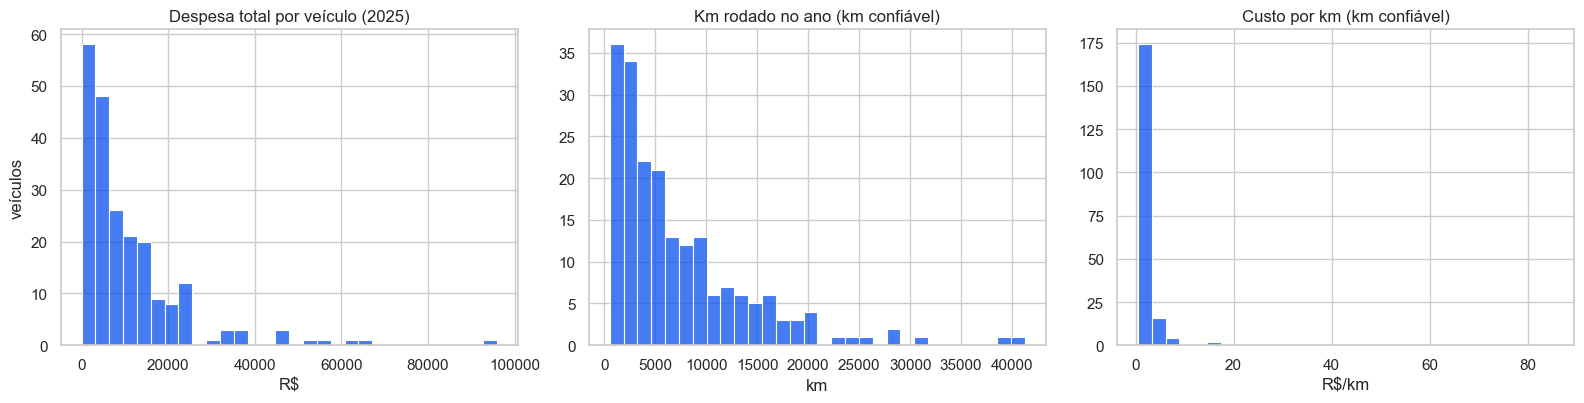

Assimetria (skew): despesa total 2.88 | km 1.98 | custo por km 10.07


In [14]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4.2))
sns.histplot(frota["despesa_total"], bins=30, ax=ax[0], color="#0750ED")
ax[0].set(title="Despesa total por veículo (2025)", xlabel="R$", ylabel="veículos")
sns.histplot(validos["km"], bins=30, ax=ax[1], color="#0750ED")
ax[1].set(title="Km rodado no ano (km confiável)", xlabel="km", ylabel="")
sns.histplot(validos["custo_km"], bins=30, ax=ax[2], color="#0750ED")
ax[2].set(title="Custo por km (km confiável)", xlabel="R$/km", ylabel="")
plt.tight_layout(); plt.show()

print("Assimetria (skew): despesa total %.2f | km %.2f | custo por km %.2f"
      % (frota["despesa_total"].skew(), validos["km"].skew(), validos["custo_km"].skew()))

As três distribuições têm cauda longa à direita: a maioria dos veículos gasta pouco e alguns concentram muito. Para um modelo de regressão isso indica testar o alvo em **escala log** e usar métricas que não sejam dominadas por poucos veículos (MAE e MAPE junto com o RMSE).

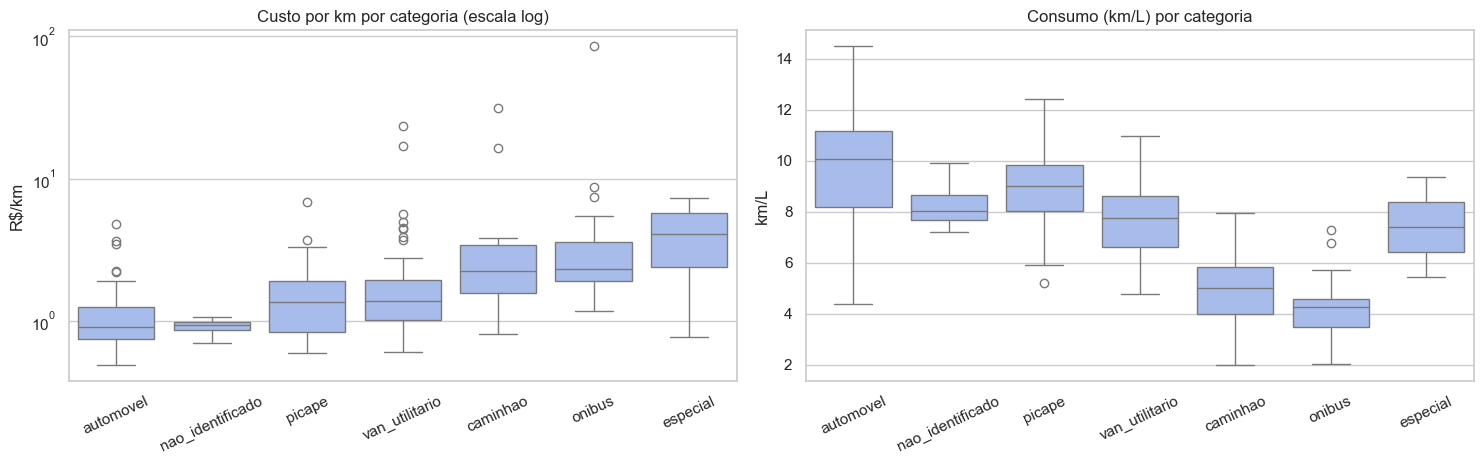

In [15]:
ordem = validos.groupby("categoria")["custo_km"].median().sort_values().index
fig, ax = plt.subplots(1, 2, figsize=(15, 4.8))
sns.boxplot(data=validos, x="categoria", y="custo_km", order=ordem, ax=ax[0], color="#9DB8F7")
ax[0].set_yscale("log")
ax[0].set(title="Custo por km por categoria (escala log)", xlabel="", ylabel="R$/km"); ax[0].tick_params(axis="x", rotation=25)
sns.boxplot(data=validos, x="categoria", y="km_l", order=ordem, ax=ax[1], color="#9DB8F7")
ax[1].set(title="Consumo (km/L) por categoria", xlabel="", ylabel="km/L"); ax[1].tick_params(axis="x", rotation=25)
plt.tight_layout(); plt.show()

In [16]:
def outliers_iqr(grupo, coluna):
    q1, q3 = grupo[coluna].quantile([0.25, 0.75])
    limite = q3 + 1.5 * (q3 - q1)
    return grupo[grupo[coluna] > limite]

fora_do_padrao = pd.concat([outliers_iqr(g, "custo_km") for _, g in validos.groupby("categoria") if len(g) >= 5])
print(f"Veículos com custo por km acima do padrão da própria categoria (regra do IQR, categorias com 5+ veículos): {len(fora_do_padrao)}")
fora_do_padrao[["placa", "modelo", "categoria", "km", "custo_km", "custo_manutencao", "abastecimento", "peso_manutencao"]] \
    .sort_values("custo_km", ascending=False)

Veículos com custo por km acima do padrão da própria categoria (regra do IQR, categorias com 5+ veículos): 20


,placa,modelo,categoria,km,custo_km,custo_manutencao,abastecimento,peso_manutencao
11,GMF3302,RODOVIARIO,onibus,617.00,85.23,"50,169.85","2,415.83",0.95
1,GMF1396,CAMINHAO,caminhao,698.00,31.53,"19,221.40","2,785.84",0.87
81,GMF6844,KOMBI,van_utilitario,"4,104.00",23.36,"92,649.17","3,215.73",0.97
32,GMF5171,VAN FURGAO,van_utilitario,"2,245.00",16.87,"35,521.18","2,346.37",0.94
13,GMF4336,CAMINHAO,caminhao,"2,235.00",16.58,"34,040.81","3,014.86",0.92
62,GMF5986,COMIL,onibus,"7,353.00",8.76,"48,972.11","15,459.67",0.76
150,GMF8352,COMIL,onibus,"3,210.00",7.40,"17,258.99","6,479.13",0.73
87,GMF6891,SAVEIRO 1.6 CE,picape,"1,152.00",6.87,"6,795.93","1,118.69",0.86
22,GMF5091,KOMBI,van_utilitario,662.00,5.63,"3,041.64",683.61,0.82
110,GMF7189,VAN DAYLE,van_utilitario,"4,541.00",4.96,"17,358.36","5,163.44",0.77


Esses veículos são o tipo de alerta que o produto da Fleet Force deve dar: **comparar cada veículo com os pares da mesma categoria**, não com a média da frota inteira (um ônibus sempre vai custar mais por km que um carro). Na maioria deles o que puxa o custo para cima é a manutenção, não o combustível (coluna `peso_manutencao`).

## 7. Relações com o problema de negócio

### 7.1 Onde está o dinheiro

,veiculos,despesa_total,abastecimento,manutencao,km_validos,fatia_da_despesa,fatia_da_frota,despesa_media_veiculo
categoria,,,,,,,,
automovel,82,"634,818.34","404,135.60","230,682.75","646,960.00",0.27,0.38,"7,741.69"
onibus,25,"629,529.26","341,212.92","288,316.34","200,676.00",0.27,0.12,"25,181.17"
van_utilitario,50,"496,994.15","224,751.51","272,242.64","253,477.00",0.21,0.23,"9,939.88"
picape,36,"302,494.95","163,751.72","138,743.23","210,912.00",0.13,0.17,"8,402.64"
caminhao,17,"248,083.71","125,297.63","122,786.08","85,472.00",0.10,0.08,"14,593.16"
nao_identificado,4,"34,930.25","33,754.80","1,175.45","40,427.00",0.01,0.02,"8,732.56"
especial,3,"20,666.08","10,996.81","9,669.27","13,515.00",0.01,0.01,"6,888.69"


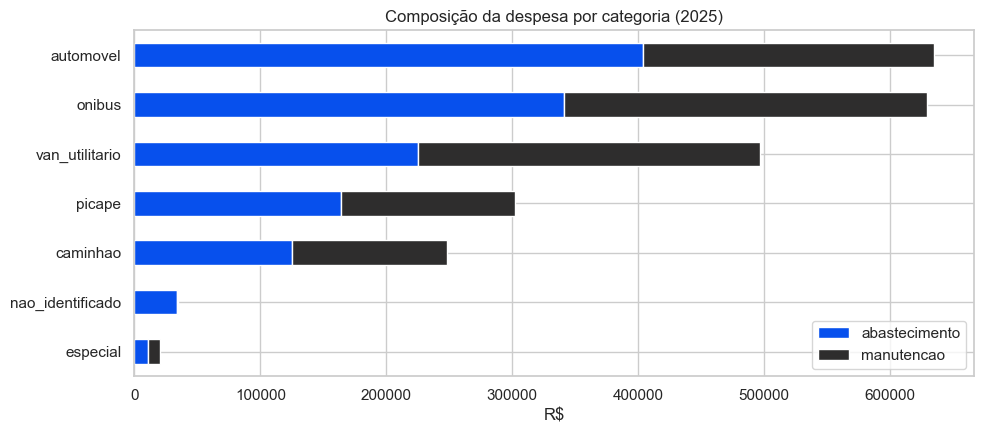

In [17]:
por_cat = (frota.groupby("categoria")
                .agg(veiculos=("placa", "size"), despesa_total=("despesa_total", "sum"),
                     abastecimento=("abastecimento", "sum"), manutencao=("custo_manutencao", "sum"),
                     km_validos=("km", lambda s: s[frota.loc[s.index, "uso_km_valido"]].sum()))
                .sort_values("despesa_total", ascending=False))
por_cat["fatia_da_despesa"] = por_cat["despesa_total"] / por_cat["despesa_total"].sum()
por_cat["fatia_da_frota"] = por_cat["veiculos"] / por_cat["veiculos"].sum()
por_cat["despesa_media_veiculo"] = por_cat["despesa_total"] / por_cat["veiculos"]
display(por_cat)

ax = por_cat[["abastecimento", "manutencao"]].plot(kind="barh", stacked=True, figsize=(10, 4.5),
                                                   color=["#0750ED", "#2E2D2D"])
ax.set(title="Composição da despesa por categoria (2025)", xlabel="R$", ylabel=""); ax.invert_yaxis()
plt.tight_layout(); plt.show()

Os 44 veículos mais caros (20% da frota) somam 56% da despesa total.
Metade da despesa está concentrada em 36 veículos.


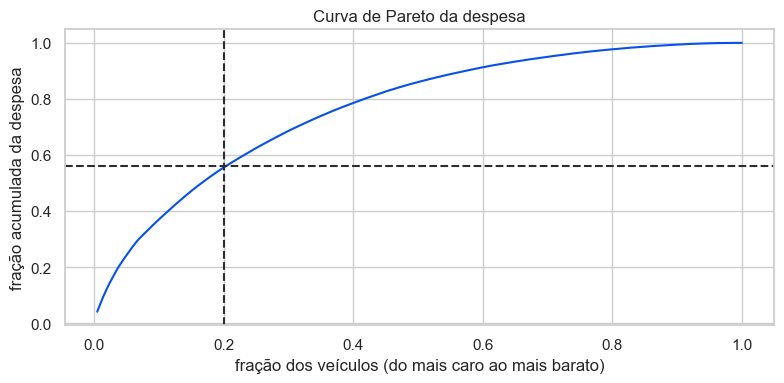

In [18]:
ordenado = frota.sort_values("despesa_total", ascending=False)
acumulado = ordenado["despesa_total"].cumsum() / ordenado["despesa_total"].sum()
n20 = int(np.ceil(0.2 * len(frota)))
print(f"Os {n20} veículos mais caros (20% da frota) somam {acumulado.iloc[n20 - 1]:.0%} da despesa total.")
print(f"Metade da despesa está concentrada em {int((acumulado < 0.5).sum()) + 1} veículos.")

plt.figure(figsize=(8, 4))
plt.plot(np.arange(1, len(frota) + 1) / len(frota), acumulado.values, color="#0750ED")
plt.axvline(0.2, ls="--", color="#2E2D2D"); plt.axhline(acumulado.iloc[n20 - 1], ls="--", color="#2E2D2D")
plt.title("Curva de Pareto da despesa"); plt.xlabel("fração dos veículos (do mais caro ao mais barato)")
plt.ylabel("fração acumulada da despesa"); plt.tight_layout(); plt.show()

### 7.2 Padrão de uso: quanto mais roda, quanto mais gasta?

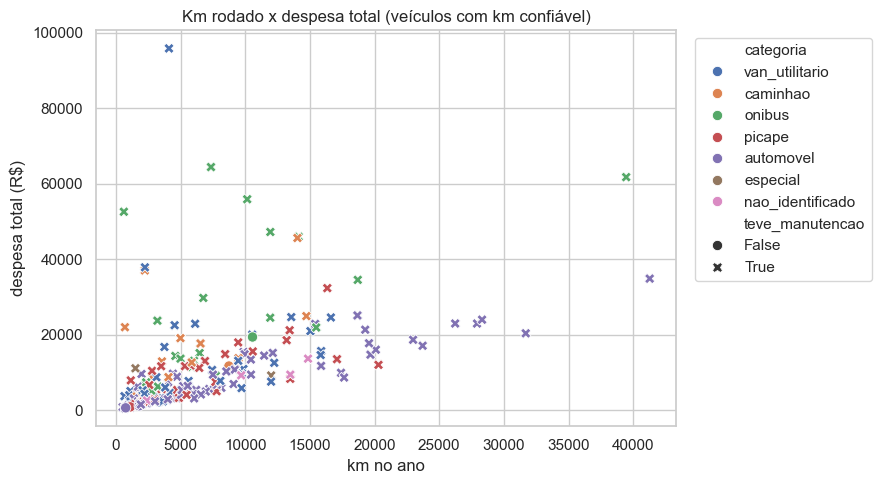

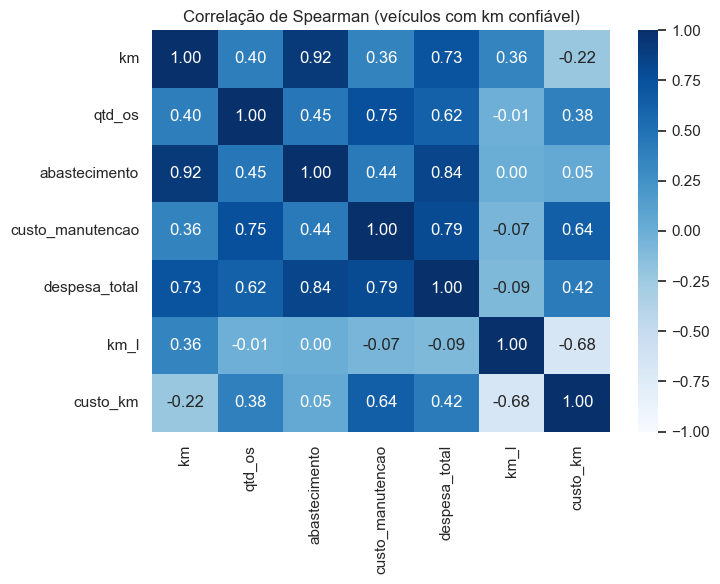

In [19]:
plt.figure(figsize=(9, 5))
sns.scatterplot(data=validos, x="km", y="despesa_total", hue="categoria", style="teve_manutencao", s=55)
plt.title("Km rodado x despesa total (veículos com km confiável)")
plt.xlabel("km no ano"); plt.ylabel("despesa total (R$)"); plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout(); plt.show()

corr_cols = ["km", "qtd_os", "abastecimento", "custo_manutencao", "despesa_total", "km_l", "custo_km"]
plt.figure(figsize=(7.5, 6))
sns.heatmap(validos[corr_cols].corr(method="spearman"), annot=True, fmt=".2f", cmap="Blues", vmin=-1, vmax=1)
plt.title("Correlação de Spearman (veículos com km confiável)"); plt.tight_layout(); plt.show()

In [20]:
r = validos[corr_cols].corr(method="spearman")
print(f"km x abastecimento ........ {r.loc['km', 'abastecimento']:.2f}")
print(f"km x custo de manutenção .. {r.loc['km', 'custo_manutencao']:.2f}")
print(f"qtd de OS x manutenção .... {r.loc['qtd_os', 'custo_manutencao']:.2f}")
print(f"km x custo por km ......... {r.loc['km', 'custo_km']:.2f}")

km x abastecimento ........ 0.92
km x custo de manutenção .. 0.36
qtd de OS x manutenção .... 0.75
km x custo por km ......... -0.22


Usamos Spearman (correlação de postos) porque as variáveis têm cauda longa e alguns valores extremos; Pearson seria puxado por poucos veículos.

### 7.3 Preço do combustível (ANP, Minas Gerais, 1º semestre de 2026)

,count,mean,50%,min,max
produto,,,,,
DIESEL,"6,108.00",6.59,6.65,5.39,8.39
DIESEL S10,"8,353.00",6.78,6.89,5.49,9.08
ETANOL,"11,263.00",4.57,4.59,3.38,5.55
GASOLINA,"11,928.00",6.34,6.34,5.29,7.39


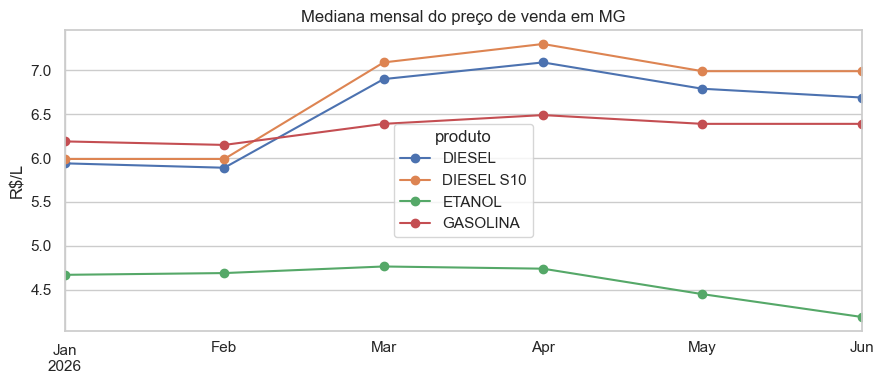

Faixa de bomba em MG (percentis 5 a 95, todos os produtos acima): R$ 3.94 a R$ 7.79/L
Veículos válidos com preço implícito fora dessa faixa (com 15% de folga, porque o relatório é de 2025): 0


,placa,modelo,categoria,km,km_l,abastecimento,preco_implicito_litro


In [21]:
principais = ["GASOLINA", "ETANOL", "DIESEL", "DIESEL S10"]
anp_p = anp[anp["produto"].isin(principais)]
display(anp_p.groupby("produto")["preco_venda"].describe()[["count", "mean", "50%", "min", "max"]])

mensal = (anp_p.assign(mes=anp_p["data_coleta"].dt.to_period("M").dt.to_timestamp())
               .groupby(["mes", "produto"])["preco_venda"].median().unstack())
ax = mensal.plot(marker="o", figsize=(9, 4))
ax.set(title="Mediana mensal do preço de venda em MG", xlabel="", ylabel="R$/L"); plt.tight_layout(); plt.show()

ref = anp_p.groupby("produto")["preco_venda"].quantile([0.05, 0.95]).unstack()
faixa_min, faixa_max = ref.min().min(), ref.max().max()
print(f"Faixa de bomba em MG (percentis 5 a 95, todos os produtos acima): R$ {faixa_min:.2f} a R$ {faixa_max:.2f}/L")
fora_preco = validos[~validos["preco_implicito_litro"].between(faixa_min * 0.85, faixa_max * 1.15)]
print(f"Veículos válidos com preço implícito fora dessa faixa (com 15% de folga, porque o relatório é de 2025): {len(fora_preco)}")
display(fora_preco[["placa", "modelo", "categoria", "km", "km_l", "abastecimento", "preco_implicito_litro"]])

In [22]:
gasto_pesados = frota.loc[frota["categoria"].isin(["onibus", "caminhao"]), "abastecimento"].sum()
print("Sensibilidade (o que um aumento de 10% no combustível faria com a despesa de 2025):")
print(f"  frota toda: + R$ {0.10 * frota['abastecimento'].sum():,.2f} no ano")
print(f"  só ônibus e caminhões (em geral a diesel): + R$ {0.10 * gasto_pesados:,.2f} no ano")

Sensibilidade (o que um aumento de 10% no combustível faria com a despesa de 2025):
  frota toda: + R$ 130,390.10 no ano
  só ônibus e caminhões (em geral a diesel): + R$ 46,651.06 no ano


O preço da ANP entra no projeto de duas formas: como **variável externa** do modelo da Sprint 3 (o custo de combustível de um mês depende do preço daquele mês) e como **teste de sanidade** do volume abastecido (preço implícito fora da faixa de bomba denunciaria litros ou valores lançados errado; em 2025 nenhum veículo válido ficou fora).

## 8. Principais insights

In [23]:
total = frota["despesa_total"].sum()
ins = {
    "veiculos": len(frota),
    "duplicata": 16_040.24,
    "fatia_abast": frota["abastecimento"].sum() / total,
    "fatia_manut": frota["custo_manutencao"].sum() / total,
    "pct_validos": frota["uso_km_valido"].mean(),
    "top20": acumulado.iloc[n20 - 1],
    "onibus_fatia_despesa": por_cat.loc["onibus", "fatia_da_despesa"],
    "onibus_fatia_frota": por_cat.loc["onibus", "fatia_da_frota"],
    "sem_manut": (~frota["teve_manutencao"]).mean(),
}
for k, v in ins.items():
    print(f"{k:24s} {v:,.3f}")

veiculos                 217.000
duplicata                16,040.240
fatia_abast              0.551
fatia_manut              0.449
pct_validos              0.917
top20                    0.559
onibus_fatia_despesa     0.266
onibus_fatia_frota       0.115
sem_manut                0.078


1. **Dados reais resolvem a dúvida de representatividade da Sprint 1**, mas exigem limpeza: o relatório oficial soma uma linha duplicada (R$ 16.040,24 a mais), divide 12 veículos em várias linhas e tem 18 veículos (8%) com km ausente, baixo demais ou impossível. Depois da limpeza ficam 217 veículos e R$ 2,37 milhões de despesa em 2025.
2. **Manutenção não é detalhe: é 45% do custo** (combustível é 55%). Um produto que olhe só o abastecimento enxerga pouco mais da metade do problema.
3. **O custo é concentrado.** 20% dos veículos respondem por 56% da despesa, e metade de todo o gasto está em 36 veículos. O gestor ganha mais olhando primeiro essa lista do que a frota inteira.
4. **Tipo de veículo é a variável que mais separa custo.** Ônibus são 12% da frota e 27% da despesa (média de R$ 25,2 mil por veículo, contra R$ 7,7 mil dos automóveis e R$ 8,4 mil das picapes). Comparar um veículo com a média geral gera alerta errado; a comparação tem que ser dentro da categoria.
5. **Combustível e manutenção têm motores diferentes.** O km explica o gasto com combustível (Spearman 0,92), mas pouco a manutenção (0,36), que acompanha o número de ordens de serviço (0,75). Para a Sprint 3 isso sugere **dois alvos separados**: combustível em função de km, categoria e preço da ANP; manutenção em função do histórico de OS (e de idade do veículo, que esta base não tem).
6. **Veículo que roda pouco custa mais por km** (Spearman de km com custo por km: -0,22). Os 20 veículos acima do padrão da própria categoria têm de 63% a 97% do gasto em manutenção, e 18 deles rodaram menos que a mediana da frota (mediana de 2,1 mil km no ano, contra 5 mil dos veículos válidos): são candidatos a revisão de uso, remanejamento ou venda, que é exatamente a decisão que a Fleet Force quer apoiar.
7. **O dado frágil é o hodômetro, não o combustível.** Litros e valores abastecidos são coerentes com o preço de bomba até nos veículos com km/L absurdo. Para o produto: validar o km na entrada (km/L fora da faixa da categoria vira alerta de cadastro, antes de virar alerta de custo).
8. **Preço do combustível pesa.** Com o perfil de 2025, cada 10% de aumento no combustível custa cerca de R$ 130 mil a mais por ano para essa frota, o que justifica usar a série da ANP como variável do modelo.

## 9. Base pronta para a Sprint 3

A base limpa (um veículo por linha, com categoria e marcações de qualidade) é salva para o modelo. Também deixamos a **divisão holdout de 20% com `random_state=42`** feita antes de qualquer ajuste, como na aula 9, estratificada por categoria para o teste ter todos os tipos de veículo.

In [24]:
from sklearn.model_selection import train_test_split

colunas_modelo = ["placa", "modelo", "categoria", "modelo_generico", "linhas_no_pdf", "qtd_os", "km", "km_l",
                  "abastecimento", "custo_manutencao", "pecas", "pneus", "despesa_total", "custo_km",
                  "peso_manutencao", "teve_manutencao", "preco_implicito_litro", "uso_km_valido", "qualidade_km"]
frota[colunas_modelo].to_csv(DADOS / "frota_ufmg_2025_limpa.csv", index=False)

base_modelo = frota[frota["uso_km_valido"]].copy()
cat_estrato = base_modelo["categoria"].where(base_modelo["categoria"].map(base_modelo["categoria"].value_counts()) >= 5, "outras")
treino, teste = train_test_split(base_modelo, test_size=0.2, random_state=SEMENTE, stratify=cat_estrato)
print(f"Base limpa salva: {len(frota)} veículos | base de modelagem (km confiável): {len(base_modelo)}")
print(f"Treino: {len(treino)} | Teste: {len(teste)}")

# baseline de referência para a Sprint 3: custo por km mediano da categoria (calculado só no treino)
mediana_cat = treino.groupby("categoria")["custo_km"].median()
prev = teste["categoria"].map(mediana_cat).fillna(treino["custo_km"].median()) * teste["km"]
erro = teste["despesa_total"] - prev
print(f"Baseline 'custo/km mediano da categoria x km' no teste: MAE R$ {erro.abs().mean():,.2f} | "
      f"RMSE R$ {np.sqrt((erro ** 2).mean()):,.2f} | MAPE {(erro.abs() / teste['despesa_total']).mean():.0%}")

Base limpa salva: 217 veículos | base de modelagem (km confiável): 199
Treino: 159 | Teste: 40
Baseline 'custo/km mediano da categoria x km' no teste: MAE R$ 4,318.79 | RMSE R$ 7,279.95 | MAPE 36%


**Por que a validação temporal pedida no feedback fica para a Sprint 3.** O relatório da UFMG é **anual por veículo**: uma linha por placa para 2025 inteiro. Sem a série mês a mês não existe divisão temporal possível nem o baseline "gasto do mês anterior" da Sprint 1. O baseline acima (custo por km mediano da categoria) é a referência que qualquer modelo da Sprint 3 terá que superar em MAE, RMSE e MAPE. Para a validação temporal, o próximo passo é pedir à UFMG (ou a um cliente piloto da Sem Parar) o mesmo relatório por mês, que o SISFROTA gera com o filtro de datas.

## 10. Limites desta análise

* **Uma frota só, de um órgão público de MG.** A UFMG não é uma transportadora: o uso (campus, transporte de alunos, ambulância) é diferente de uma frota comercial típica da Sem Parar. Os padrões valem como hipóteses a testar em clientes, não como regra.
* **Um ano agregado.** Não dá para ver sazonalidade nem tendência.
* **Categoria inferida do rótulo do modelo**, com alguns casos decididos pelo consumo; rótulos genéricos ficaram como `nao_identificado`.
* **Faixas de km/L e corte de 500 km são critérios de triagem**, escolhidos para separar erro grosseiro de dado plausível, não especificação de fábrica.
* **A ANP é do 1º semestre de 2026 e o relatório é de 2025.** A comparação de preço implícito é aproximada (por isso a folga de 15%).
* **Sem dados de seguro, pedágio, multas e depreciação**, que fazem parte do custo total de propriedade.